# Day 10 – Introduction to Machine Learning: Linear Regression

**Internship Domain:** Artificial Intelligence and Machine Learning

This notebook demonstrates the basic ML workflow using a small synthetic practice dataset. It is illustrative, not real student data.

## 1. Import libraries
Install dependencies with `pip install -r requirements.txt` if needed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load and inspect the dataset

In [2]:
df = pd.read_csv("../data/study_hours_marks.csv")
display(df.head())
print("Shape:", df.shape)
print(df.describe())

,study_hours,exam_marks
0,1.0,35
1,1.5,38
2,2.0,42
3,2.5,45
4,3.0,49


Shape: (20, 2)
       study_hours  exam_marks
count     20.00000    20.00000
mean       5.75000    65.75000
std        2.95804    18.88713
min        1.00000    35.00000
25%        3.37500    50.50000
50%        5.75000    66.00000
75%        8.12500    80.75000
max       10.50000    96.00000


## 3. Define features and target

In [3]:
X = df[["study_hours"]]
y = df["exam_marks"]

## 4. Split data into training and testing sets

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16
Testing samples: 4


## 5. Train the Linear Regression model

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 6.3682702458151095
Intercept: 29.26240386065451


## 6. Make predictions

In [6]:
y_pred = model.predict(X_test)
predictions = pd.DataFrame({
    "Study Hours": X_test["study_hours"].values,
    "Actual Marks": y_test.values,
    "Predicted Marks": y_pred
}).sort_values("Study Hours")
display(predictions)

,Study Hours,Actual Marks,Predicted Marks
0,1.0,35,35.630674
3,1.5,38,38.814809
2,8.5,83,83.392701
1,9.5,89,89.760971


## 7. Evaluate the model

In [7]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.3f}")

MAE: 0.65
MSE: 0.45
RMSE: 0.67
R² Score: 0.999


## 8. Visualize the regression line

c:\Users\Jagadish\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


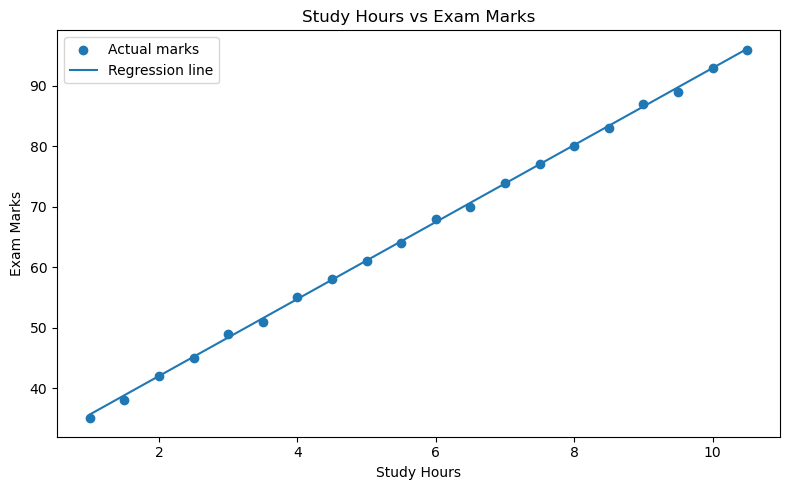

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(df["study_hours"], df["exam_marks"], label="Actual marks")
x_line = np.linspace(df["study_hours"].min(), df["study_hours"].max(), 100).reshape(-1, 1)
plt.plot(x_line, model.predict(x_line), label="Regression line")
plt.xlabel("Study Hours")
plt.ylabel("Exam Marks")
plt.title("Study Hours vs Exam Marks")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Predict a new value

In [9]:
new_data = pd.DataFrame({"study_hours": [6.0]})
print("Predicted marks for 6 study hours:", round(model.predict(new_data)[0], 2))

Predicted marks for 6 study hours: 67.47


## 10. Save prediction results

In [10]:
import os
os.makedirs("../outputs", exist_ok=True)
predictions.to_csv("../outputs/test_predictions.csv", index=False)
print("Saved: outputs/test_predictions.csv")

Saved: outputs/test_predictions.csv


## Conclusion
The notebook covers data loading, feature/target selection, train/test splitting, model training, prediction, evaluation, and visualization.